In [1]:
import os

for root, dirs, files in os.walk('/kaggle/input'):
    print("Folder:", root)
    for file in files:
        print("  File:", file)

Folder: /kaggle/input
Folder: /kaggle/input/datasets
Folder: /kaggle/input/datasets/batooljuaitem
Folder: /kaggle/input/datasets/batooljuaitem/smv-com
  File: adam.json
  File: gd.json
  File: mini-batch-gd.json
  File: rmsprop.json
  File: sgd.json
Folder: /kaggle/input/datasets/batooljuaitem/predict-students-dropout-and-academic-success
  File: data.csv


In [2]:
import matplotlib.pyplot as plt
import numpy as np
import pandas as pd

print("All libraries imported successfully!")

All libraries imported successfully!


In [3]:

import os
import json

DATA_DIR = "/kaggle/input/datasets/batooljuaitem/smv-com"

ORDER = ["gd", "sgd", "mini-batch-gd", "rmsprop", "adam"]

R = {}

for name in ORDER:
    path = os.path.join(DATA_DIR, f"{name}.json")

    with open(path, "r") as f:
        R[name] = json.load(f)

print("All result files loaded successfully!")

for name in ORDER:
    print(name, ":", type(R[name]))


All result files loaded successfully!
gd : <class 'dict'>
sgd : <class 'dict'>
mini-batch-gd : <class 'dict'>
rmsprop : <class 'dict'>
adam : <class 'dict'>


In [4]:

import numpy as np

# Consistency checks
def unique(key_fn):
    return {key_fn(R[s]) for s in ORDER}

checks = {
    "split fingerprint": unique(lambda r: r["split_fingerprint"]),
    "seed": unique(lambda r: r["seed"]),
    "n_train": unique(lambda r: r["n_train"]),
    "n_test": unique(lambda r: r["n_test"]),
    "n_features": unique(lambda r: r["n_features"]),
    "epochs": unique(lambda r: r["hyperparameters"]["epochs"]),
    "lambda": unique(lambda r: r["hyperparameters"]["lambda"]),
    "test confusion-matrix row sums": unique(
        lambda r: tuple(np.array(r["confusion_matrix"]).sum(axis=1))
    ),
}

for k, v in checks.items():
    print(f"{k:35}: {v}")


split fingerprint                  : {'84af02e7b2f6d02b'}
seed                               : {42}
n_train                            : {3539}
n_test                             : {885}
n_features                         : {237}
epochs                             : {100.0}
lambda                             : {0.001}
test confusion-matrix row sums     : {(np.int64(284), np.int64(159), np.int64(442))}


In [5]:
import pandas as pd

rows = []

for name in ORDER:
    m = R[name]["metrics"]

    rows.append({
        "Optimizer": name.upper(),
        "Learning rate": R[name]["learning_rate"],
        "Accuracy": m["accuracy"],
        "Precision (macro)": m["precision_macro"],
        "Recall (macro)": m["recall_macro"],
        "F1 (macro)": m["f1_macro"],
        "Final training loss": m["final_train_loss"]
    })

table = pd.DataFrame(rows).set_index("Optimizer")

display(
    table.style.format({
        "Learning rate": "{:.0e}",
        **{c: "{:.4f}" for c in table.columns if c != "Learning rate"}
    }).highlight_max(
        subset=["Accuracy", "Precision (macro)", "Recall (macro)", "F1 (macro)"],
        color="#c7e9c0"
    )
)

,Learning rate,Accuracy,Precision (macro),Recall (macro),F1 (macro),Final training loss
Optimizer,,,,,,
GD,3e-01,0.7559,0.6930,0.6465,0.6482,0.4546
SGD,1e-04,0.7582,0.6938,0.6537,0.6606,0.4597
MINI-BATCH-GD,1e-02,0.7695,0.7109,0.6659,0.6724,0.4584
RMSPROP,1e-04,0.7537,0.6873,0.6455,0.6480,0.4565
ADAM,1e-03,0.7571,0.6936,0.6486,0.6512,0.4524


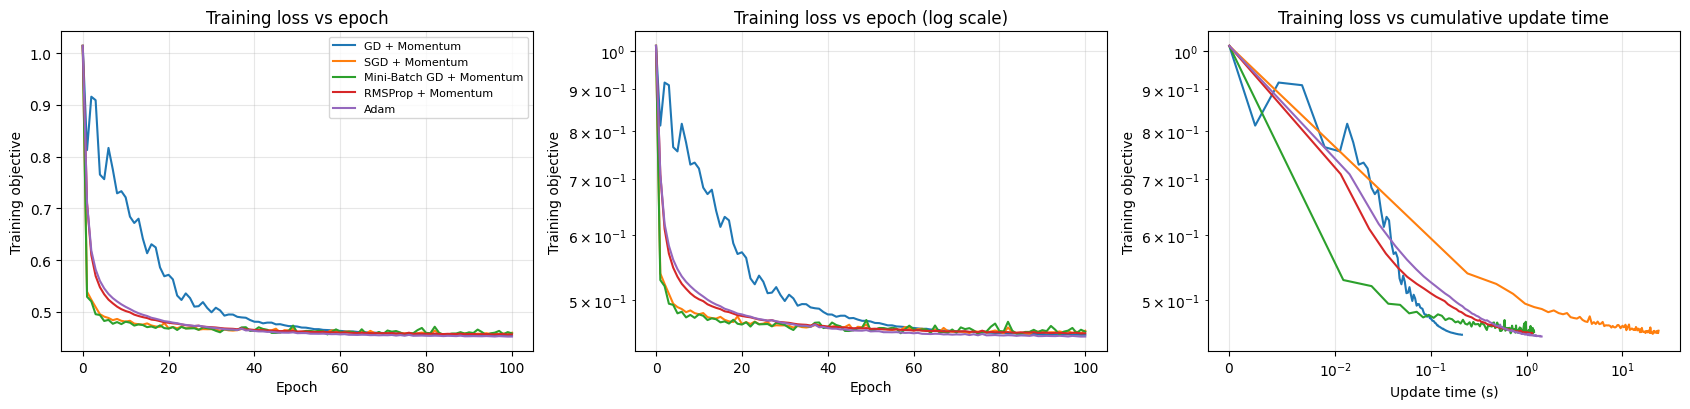

,Initial loss,Final loss,Epochs to 95% reduction,Time to 95% (s),Total update time (s),Epochs with loss increase
Optimizer,,,,,,
GD + Momentum,1.0142,0.4546,40,0.09,0.21,20
SGD + Momentum,1.0142,0.4597,9,2.16,23.99,43
Mini-Batch GD + Momentum,1.0142,0.4584,5,0.06,1.20,47
RMSProp + Momentum,1.0142,0.4565,18,0.22,1.14,26
Adam,1.0142,0.4524,21,0.30,1.43,25


In [6]:
# 3. Convergence Analysis
import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
fig, axes = plt.subplots(1, 3, figsize=(17, 4.2))
for s in ORDER:
    r = R[s]
    L = np.array(r["loss_history"])
    t = np.concatenate([[0.0], np.cumsum(r["epoch_time"])])
    axes[0].plot(L, label=r["optimizer"])
    axes[1].plot(L, label=r["optimizer"])
    axes[2].plot(t, L, label=r["optimizer"])
axes[0].set_title("Training loss vs epoch"); axes[1].set_title("Training loss vs epoch (log scale)"); axes[1].set_yscale("log")
axes[2].set_title("Training loss vs cumulative update time"); axes[2].set_xscale("symlog", linthresh=0.01); axes[2].set_yscale("log")
axes[0].set_xlabel("Epoch"); axes[1].set_xlabel("Epoch"); axes[2].set_xlabel("Update time (s)")
for ax in axes:
    ax.set_ylabel("Training objective"); ax.grid(alpha=0.3)
axes[0].legend(fontsize=8)
plt.tight_layout(); plt.show()

conv_rows = []
for s in ORDER:
    r = R[s]; cv = r["convergence"]; L = np.array(r["loss_history"])
    conv_rows.append({"Optimizer": r["optimizer"], "Initial loss": L[0], "Final loss": L[-1],
                      "Epochs to 95% reduction": cv["epochs_to_95pct_reduction"],
                      "Time to 95% (s)": cv["time_to_95pct_reduction_sec"],
                      "Total update time (s)": cv["total_update_time_sec"],
                      "Epochs with loss increase": cv["epochs_with_loss_increase"]})
conv = pd.DataFrame(conv_rows).set_index("Optimizer")
display(conv.style.format({"Initial loss": "{:.4f}", "Final loss": "{:.4f}", "Time to 95% (s)": "{:.2f}", "Total update time (s)": "{:.2f}"}))

,F1 Dropout,F1 Enrolled,F1 Graduate,Recall Dropout,Recall Enrolled,Recall Graduate
GD + Momentum,0.7746,0.3231,0.8469,0.7746,0.2327,0.9321
SGD + Momentum,0.7647,0.3614,0.8557,0.7324,0.2830,0.9457
Mini-Batch GD + Momentum,0.7864,0.3719,0.8589,0.7711,0.2830,0.9434
RMSProp + Momentum,0.7744,0.3248,0.8448,0.7676,0.2390,0.9299
Adam,0.7801,0.3276,0.8460,0.7746,0.2390,0.9321


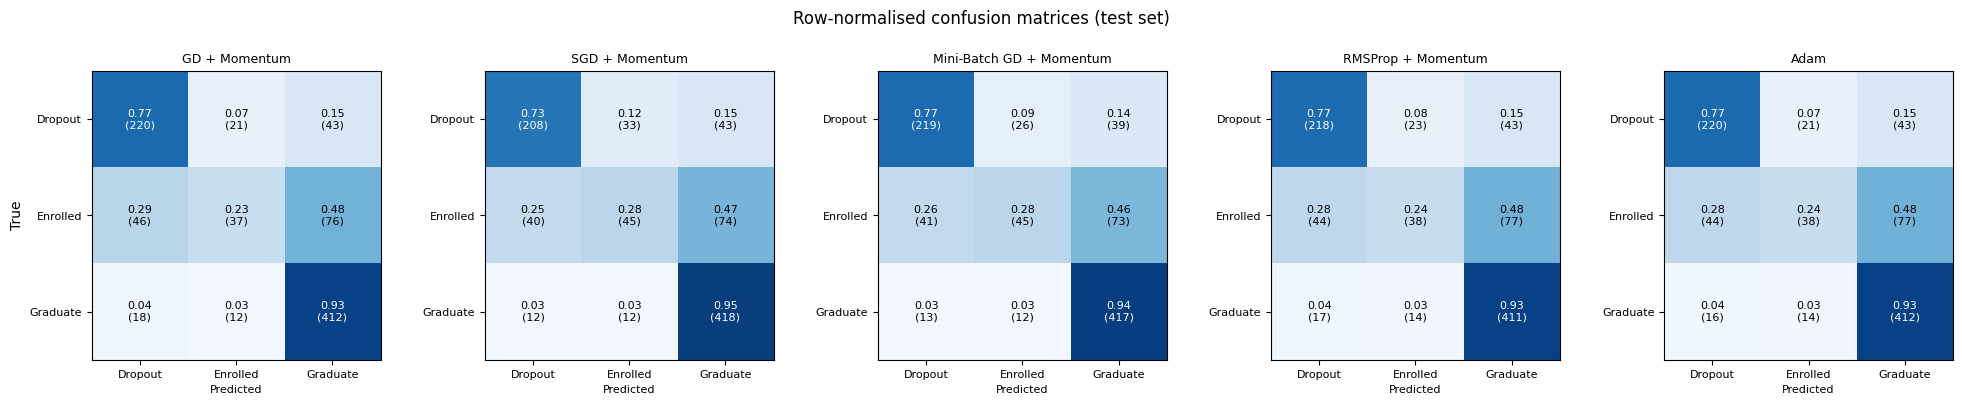

In [7]:
# 4. Per-Class Results and Confusion Matrices

CLASS_NAMES = ["Dropout", "Enrolled", "Graduate"]

pc = pd.DataFrame({
    R[s]["optimizer"]: {
        **{f"F1 {c}": R[s]["per_class"][c]["f1-score"] for c in CLASS_NAMES},
        **{f"Recall {c}": R[s]["per_class"][c]["recall"] for c in CLASS_NAMES}
    }
    for s in ORDER
}).T

display(pc.style.format("{:.4f}"))

fig, axes = plt.subplots(1, len(ORDER), figsize=(4 * len(ORDER), 3.8))

for ax, s in zip(axes, ORDER):
    cm = np.array(R[s]["confusion_matrix"])
    cmn = cm / cm.sum(axis=1, keepdims=True)

    ax.imshow(cmn, cmap="Blues", vmin=0, vmax=1)
    ax.set_xticks(range(3))
    ax.set_yticks(range(3))
    ax.set_xticklabels(CLASS_NAMES, fontsize=8)
    ax.set_yticklabels(CLASS_NAMES, fontsize=8)
    ax.set_title(R[s]["optimizer"], fontsize=9)
    ax.set_xlabel("Predicted", fontsize=8)

    for i in range(3):
        for j in range(3):
            ax.text(
                j, i,
                f"{cmn[i, j]:.2f}\n({cm[i, j]})",
                ha="center",
                va="center",
                fontsize=8,
                color="white" if cmn[i, j] > 0.5 else "black"
            )

axes[0].set_ylabel("True")
plt.suptitle("Row-normalised confusion matrices (test set)", y=1.02)
plt.tight_layout()
plt.show()

In [8]:
# 5. Discussion | 5.1 Findings measured in this run
best_f1 = table["F1 (macro)"].idxmax(); worst_f1 = table["F1 (macro)"].idxmin()
best_acc = table["Accuracy"].idxmax()
spread = table["F1 (macro)"].max() - table["F1 (macro)"].min()
fastest_epochs = conv["Epochs to 95% reduction"].idxmin()
slowest_epochs = conv["Epochs to 95% reduction"].idxmax()
lowest_loss = table["Final training loss"].idxmin()
fastest_time = conv["Time to 95% (s)"].idxmin()
noisiest = conv["Epochs with loss increase"].idxmax()
smoothest = conv["Epochs with loss increase"].idxmin()

print(f"* Best macro-F1: {best_f1} ({table.loc[best_f1, 'F1 (macro)']:.4f}); lowest: {worst_f1} ({table.loc[worst_f1, 'F1 (macro)']:.4f}). Spread between best and worst: {spread:.4f}.")
print(f"* Best accuracy: {best_acc} ({table.loc[best_acc, 'Accuracy']:.4f}).")
print(f"* Lowest final training loss: {lowest_loss} ({table.loc[lowest_loss, 'Final training loss']:.4f}).")
print(f"* Fewest epochs to 95% of the loss reduction: {fastest_epochs} ({conv.loc[fastest_epochs, 'Epochs to 95% reduction']} epochs); most: {slowest_epochs} ({conv.loc[slowest_epochs, 'Epochs to 95% reduction']} epochs).")
print(f"* Least update time to 95% of the loss reduction: {fastest_time} ({conv.loc[fastest_time, 'Time to 95% (s)']:.2f} s).")
print(f"* Smoothest loss curve (fewest epochs with an increase): {smoothest} ({conv.loc[smoothest, 'Epochs with loss increase']}); noisiest: {noisiest} ({conv.loc[noisiest, 'Epochs with loss increase']}).")
weak = {c: pc[f"F1 {c}"].mean() for c in CLASS_NAMES}
print(f"* Mean F1 per class over the five optimizers: " + ", ".join(f"{c} {v:.4f}" for c, v in weak.items()) + f" -> hardest class: {min(weak, key=weak.get)}.")
if spread < 0.02:
    print("* The five optimizers end up within 2 percentage points of macro-F1 of each other: they solve the same convex objective, so similar final accuracy is expected once the loss has (nearly) converged.")
else:
    print("* The macro-F1 spread exceeds 2 percentage points: check in the loss curves whether the weaker optimizers had simply not converged within the fixed number of epochs.")

* Best macro-F1: MINI-BATCH-GD (0.6724); lowest: RMSPROP (0.6480). Spread between best and worst: 0.0244.
* Best accuracy: MINI-BATCH-GD (0.7695).
* Lowest final training loss: ADAM (0.4524).
* Fewest epochs to 95% of the loss reduction: Mini-Batch GD + Momentum (5 epochs); most: GD + Momentum (40 epochs).
* Least update time to 95% of the loss reduction: Mini-Batch GD + Momentum (0.06 s).
* Smoothest loss curve (fewest epochs with an increase): GD + Momentum (20); noisiest: Mini-Batch GD + Momentum (47).
* Mean F1 per class over the five optimizers: Dropout 0.7761, Enrolled 0.3418, Graduate 0.8505 -> hardest class: Enrolled.
* The macro-F1 spread exceeds 2 percentage points: check in the loss curves whether the weaker optimizers had simply not converged within the fixed number of epochs.
